In [1]:

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import (
    HuberRegressor,
    LinearRegression,
    LogisticRegression,
    QuantileRegressor,
    Ridge,
    ElasticNet,
    Lasso
)
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV, train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    PolynomialFeatures,
    SplineTransformer,
    StandardScaler,
    RobustScaler
)
from ucimlrepo import fetch_ucirepo
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("QSAR_challenge_train_80pct.csv")


print(df.shape)
display(df.head())

(623, 12)


,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
0,2234-13-1,8.0,7.157,2.41,0.21,6.55,0.97,0.0,0.0,0.0,2.58,3
1,108-42-9,1.0,0.000,1.23,0.20,2.13,0.68,0.0,1.0,NaN,0.33,3
2,106-43-4,1.0,0.000,1.23,0.22,3.21,0.84,0.0,0.0,0.0,1.80,1
3,108-87-2,0.0,0.000,0.00,0.34,3.48,1.67,0.0,0.0,0.0,2.32,1
4,101-81-5,0.0,5.614,2.21,0.19,4.15,1.47,0.0,0.0,0.0,2.97,1


In [3]:
df.describe()

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
count,612.000000,610.000000,616.000000,611.000000,610.000000,609.000000,604.000000,616.000000,607.000000,623.000000,623.000000
mean,1.754902,3.349279,1.532987,0.236563,3.189770,1.496700,0.188742,0.428571,3.598023,2.046260,1.736758
std,1.993950,2.970165,0.934499,0.156650,1.584938,0.854107,0.506154,0.495274,4.491267,1.335059,0.922066
min,0.000000,0.000000,0.000000,0.090000,-1.960000,0.140000,0.000000,0.000000,0.000000,-1.700000,1.000000
25%,0.000000,0.000000,1.210000,0.170000,2.190000,0.860000,0.000000,0.000000,0.000000,0.985000,1.000000
50%,1.000000,4.025000,1.380000,0.200000,3.115000,1.260000,0.000000,0.000000,2.000000,2.000000,1.000000
75%,3.000000,6.187500,2.280000,0.240000,4.207500,1.990000,0.000000,1.000000,6.000000,2.865000,3.000000
max,12.000000,9.316000,5.330000,2.230000,8.320000,7.190000,3.000000,1.000000,25.000000,5.930000,3.000000


In [4]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_by_row = df.isna().sum(axis=1)

display(missing_by_column.to_frame("missing_count"))
display((missing_by_column / len(df)).to_frame("missing_fraction"))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))
print("Rows with more than one missing value:", int((missing_by_row > 1).sum()))

,missing_count
N-072,19
F04[C-O],16
ON1V,14
piPC09,13
MLOGP,13
X2Av,12
nHM,11
PCD,7
B02[C-N],7
sample_id,0


,missing_fraction
N-072,0.030498
F04[C-O],0.025682
ON1V,0.022472
piPC09,0.020867
MLOGP,0.020867
X2Av,0.019262
nHM,0.017657
PCD,0.011236
B02[C-N],0.011236
sample_id,0.000000


Rows with at least one missing value: 104
Rows with more than one missing value: 7


In [5]:

print("Exact duplicate rows", int(df.duplicated().sum()))

Exact duplicate rows 0


,count,mean,std,min,50%,max
nHM,612.0,1.754902,1.993950,0.00,1.000,12.000
piPC09,610.0,3.349279,2.970165,0.00,4.025,9.316
PCD,616.0,1.532987,0.934499,0.00,1.380,5.330
X2Av,611.0,0.236563,0.156650,0.09,0.200,2.230
MLOGP,610.0,3.189770,1.584938,-1.96,3.115,8.320
ON1V,609.0,1.496700,0.854107,0.14,1.260,7.190
N-072,604.0,0.188742,0.506154,0.00,0.000,3.000
B02[C-N],616.0,0.428571,0.495274,0.00,0.000,1.000
F04[C-O],607.0,3.598023,4.491267,0.00,2.000,25.000
regression_target,623.0,2.046260,1.335059,-1.70,2.000,5.930


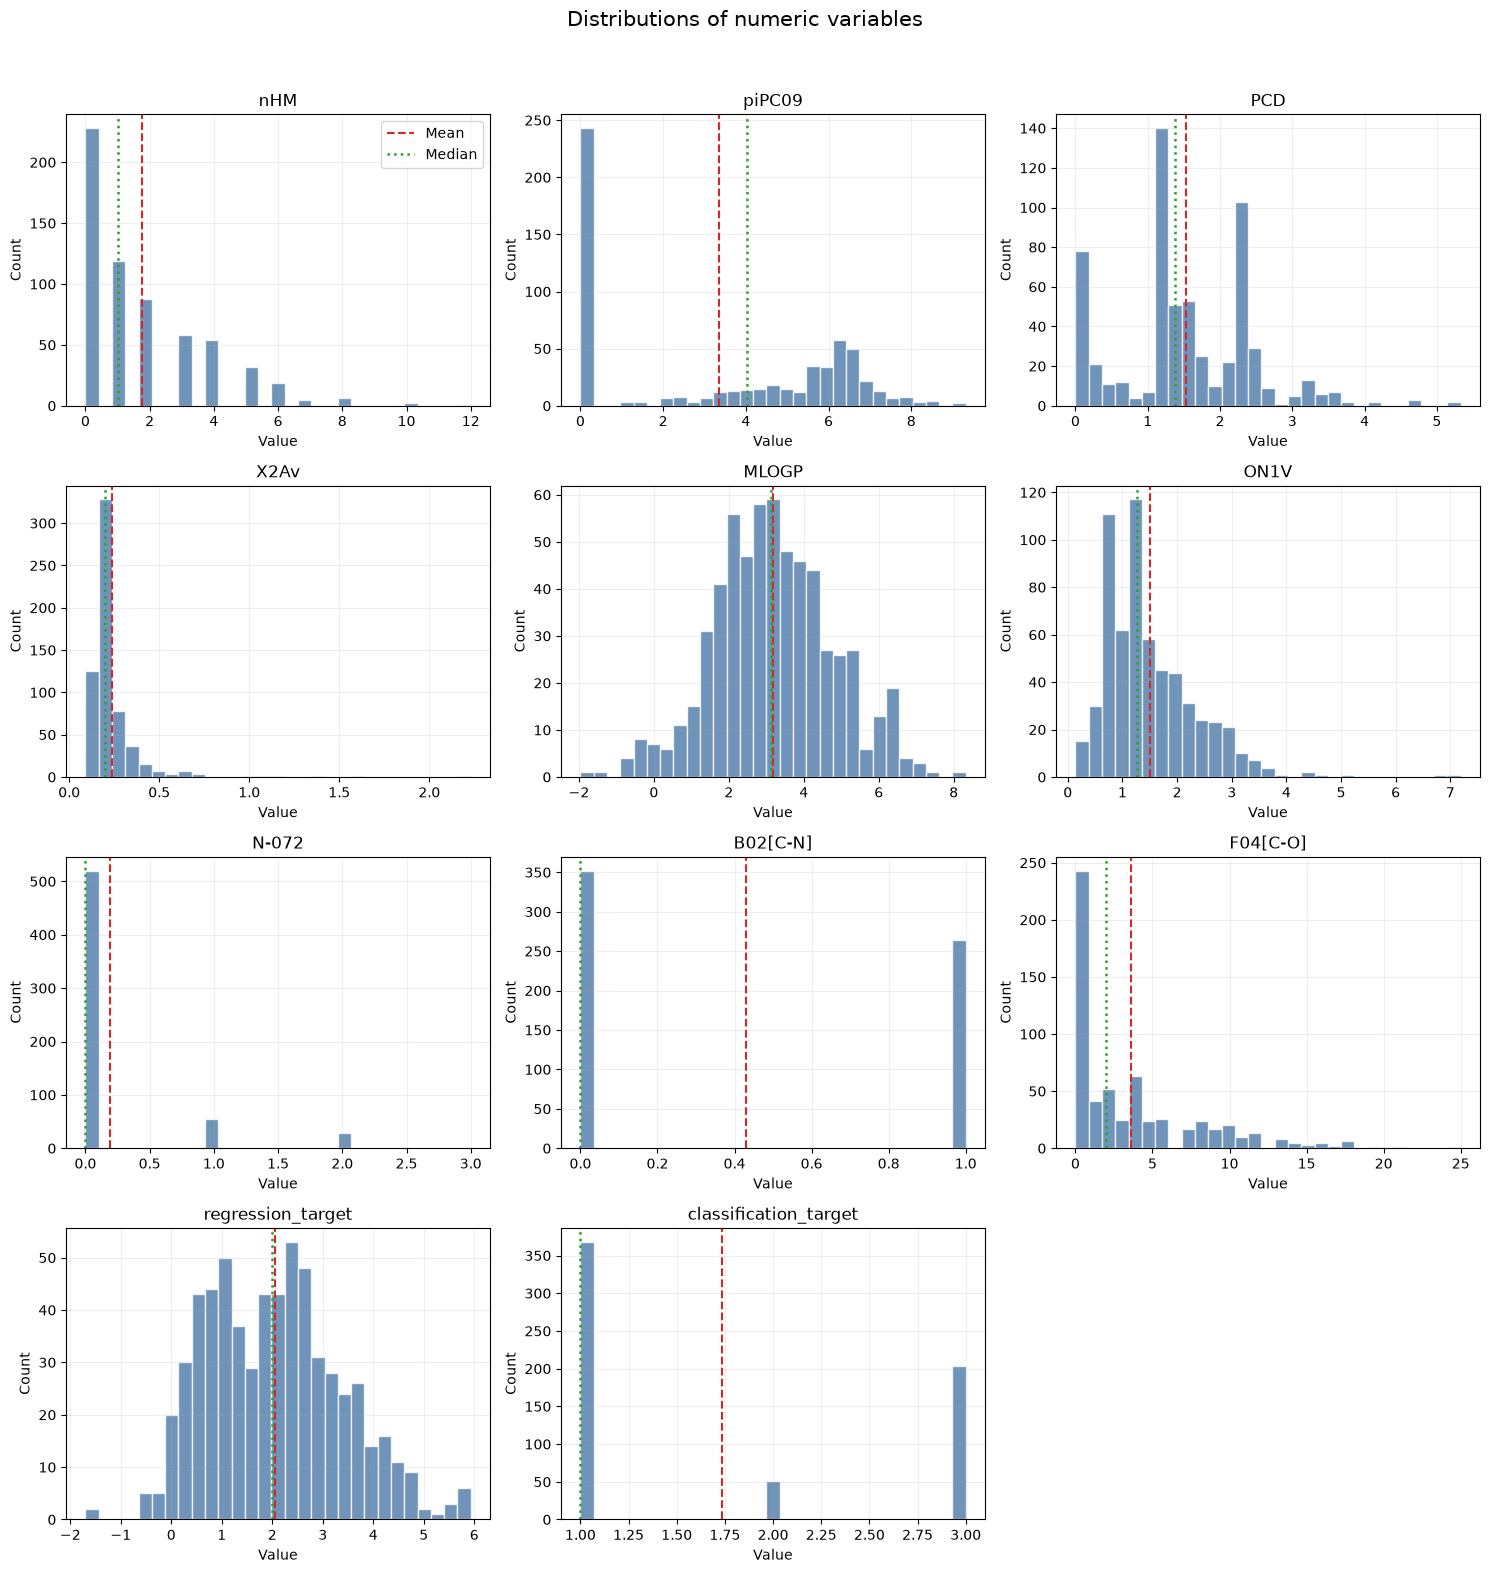

In [6]:
numeric_eda_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_eda_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]])

n_cols = 3
n_rows = int(np.ceil(len(numeric_eda_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, column in zip(axes, numeric_eda_cols):
    values = df[column].dropna()
    ax.hist(values, bins=29, color="#4c78a8", alpha=0.8, edgecolor="white")
    ax.axvline(values.mean(), color="#d62728", linestyle="--", linewidth=1.5, label="Mean")
    ax.axvline(values.median(), color="#2ca02c", linestyle=":", linewidth=1.8, label="Median")
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)

for ax in axes[len(numeric_eda_cols):]:
    ax.set_visible(False)
axes[0].legend(frameon=True)
fig.suptitle("Distributions of numeric variables", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import math

target = "regression_target" 
features = df.drop(columns=[target]).select_dtypes(include="number").columns

n_cols = 3
n_rows = math.ceil(len(features) / n_cols)

fig = make_subplots(
    rows=n_rows,
    cols=n_cols,
    subplot_titles=features
)

for i, feature in enumerate(features):
    row = i // n_cols + 1
    col = i % n_cols + 1

    scatter = px.scatter(df, x=feature, y=target)

    for trace in scatter.data:
        fig.add_trace(trace, row=row, col=col)

fig.update_layout(
    height=280 * n_rows,
    width=1100,
    showlegend=False,
    template="plotly_white",
    title="Feature vs Target"
)

fig.show()

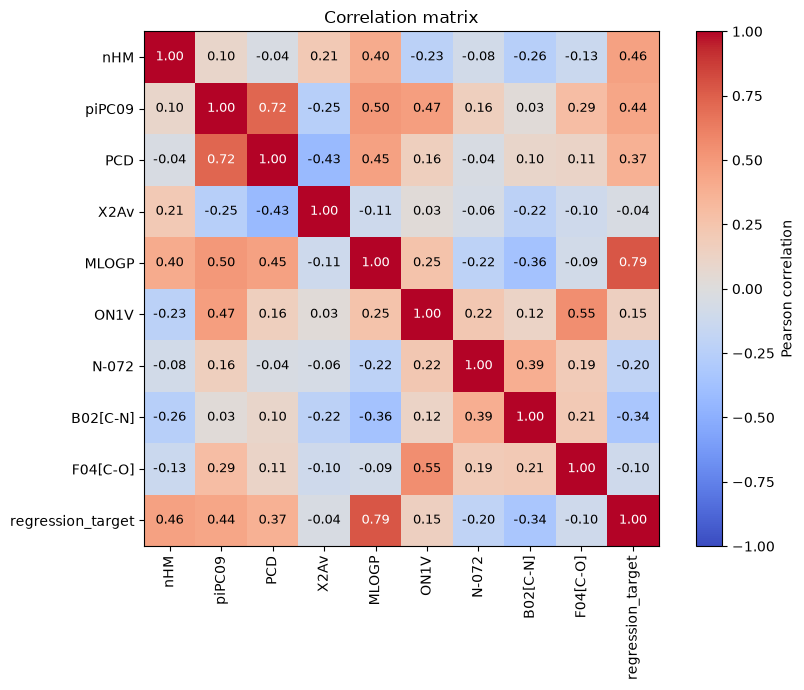

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

corr = df.drop(columns=["sample_id", "classification_target"]).corr()

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix")

plt.tight_layout()
plt.show()

In [15]:
X = df.drop(columns=["sample_id", "regression_target", "classification_target"])
y = df['regression_target']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)


print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (498, 9) Test: (125, 9)


In [17]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [18]:
def regression_metrics(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}

regression_results = []

In [19]:
def plot_observed_vs_predicted(y_true, y_pred, title):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(y_true, y_pred, alpha=0.55, color="#4c78a8")
    ax.plot([low, high], [low, high], color="#d62728", linestyle="--", linewidth=2, label="Perfect prediction")
    ax.set_xlabel("Observed Rings")
    ax.set_ylabel("Predicted Rings")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

,model,MAE,RMSE,R2
0,Linear regression,0.585873,0.79264,0.598005


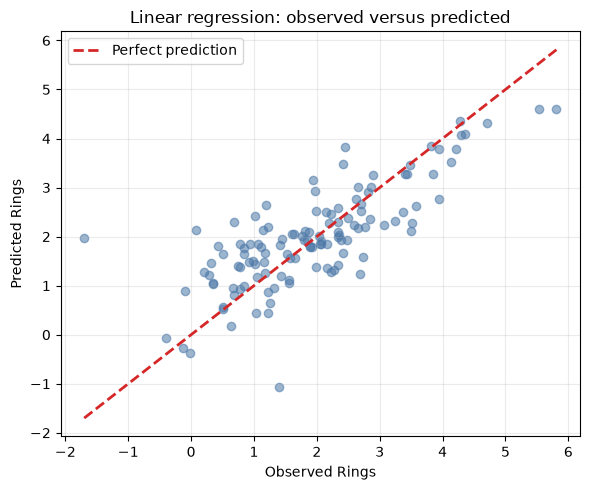

In [20]:
linear_model = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())])

linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)

regression_results.append(
    regression_metrics("Linear regression", y_test, pred_linear))

display(pd.DataFrame(regression_results))
plot_observed_vs_predicted(y_test, pred_linear, "Linear regression: observed versus predicted")

In [ ]:
num_cols =  [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]

spline_preprocessor = ColumnTransformer([
    ("num_spline",
     Pipeline([
         ("imputer", SimpleImputer(strategy="median")),
         ("scale", RobustScaler()),
         ("spline", SplineTransformer(include_bias=False))
     ]),
     num_cols)
])

spline_model = Pipeline([
    ("prep", spline_preprocessor),
    ("model", Ridge(alpha=1))
])

Best parameters: {'prep__num_spline__spline__n_knots': 4, 'prep__num_spline__spline__degree': 2, 'model__alpha': 1}
CV RMSE: 0.7876609979133707
CV R²: 0.65100387648901
Test RMSE: 0.7714459941656153
Test R²: 0.6192153997483665


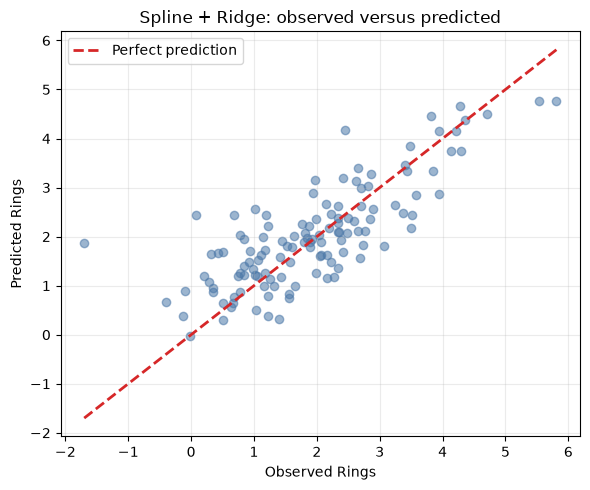

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "prep__num_spline__spline__n_knots": [3,4,6],
    "prep__num_spline__spline__degree": [2, 3],
    "model__alpha": [0.1, 1, 10, 100]
}

search = RandomizedSearchCV(
    estimator=spline_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    refit="RMSE",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_spline = search.best_estimator_

print("Best parameters:", search.best_params_)
print("CV RMSE:", -search.best_score_)
print("CV R²:", search.cv_results_["mean_test_R2"][search.best_index_])

pred_spline = best_spline.predict(X_test)

print("Test RMSE:", np.sqrt(mean_squared_error(y_test, pred_spline)))
print("Test R²:", r2_score(y_test, pred_spline))

plot_observed_vs_predicted(
    y_test,
    pred_spline,
    "Spline + Ridge: observed versus predicted"
)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from pygam import LinearGAM, l, s

feature_names = [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]

X = df[feature_names]
y = df["regression_target"].values

gam_terms = (
    l(0)  # nHM (discrete count)
    + s(1)  # piPC09 (continuous / zero-clustered)
    + s(2)  # PCD (continuous)
    + s(3)  # X2Av (continuous)
    + s(4)  # MLOGP (continuous)
    + s(5)  # ON1V (continuous)
    + l(6)  # N-072 (discrete count)
    + l(7)  # B02[C-N] (binary/discrete count)
    + l(8)  # F04[C-O] (discrete count)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_scores = []
r2_scores = []

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
    X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    X_train_prep = preprocessor.fit_transform(X_train_raw)

    X_test_prep = preprocessor.transform(X_test_raw)

    gam = LinearGAM(gam_terms)
    gam.gridsearch(X_train_prep, y_train, progress=False)

    preds = gam.predict(X_test_prep)

    fold_rmse = np.sqrt(mean_squared_error(y_test, preds))
    fold_r2 = r2_score(y_test, preds)

    rmse_scores.append(fold_rmse)
    r2_scores.append(fold_r2)
    print(f"Fold {fold+1} | RMSE: {fold_rmse:.4f} | R^2: {fold_r2:.4f}")

print("\n--- GAM Cross-Validation Results ---")
print(f"Mean RMSE: {np.mean(rmse_scores):.4f} +/- {np.std(rmse_scores):.4f}")
print(f"Mean R^2:  {np.mean(r2_scores):.4f} +/- {np.std(r2_scores):.4f}")

Fold 1 | RMSE: 0.7766 | R^2: 0.6141
Fold 2 | RMSE: 0.8244 | R^2: 0.5653
Fold 3 | RMSE: 0.7263 | R^2: 0.6802
Fold 4 | RMSE: 0.7990 | R^2: 0.7113
Fold 5 | RMSE: 0.7402 | R^2: 0.7006

--- GAM Cross-Validation Results ---
Mean RMSE: 0.7733 +/- 0.0363
Mean R^2:  0.6543 +/- 0.0559


### Classification

In [30]:
df['classification_target'].value_counts()

classification_target
1    368
3    204
2     51
Name: count, dtype: int64

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import numpy as np


X_cls = df.drop(columns=["sample_id", "regression_target", "classification_target"])
y_cls = df["classification_target"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_cls
)


classification_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression( class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


scoring = {
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro'
}


cv_results = cross_validate(
    classification_model,
    Xc_train,
    yc_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("=== Cross-Validation Results (Train Fold Means) ===")
print(f"Mean Balanced Accuracy: {np.mean(cv_results['test_balanced_accuracy']):.4f} ± {np.std(cv_results['test_balanced_accuracy']):.4f}")
print(f"Mean Macro F1:          {np.mean(cv_results['test_f1_macro']):.4f} ± {np.std(cv_results['test_f1_macro']):.4f}")
print("-" * 50)


classification_model.fit(Xc_train, yc_train)

cls_pred = classification_model.predict(Xc_test)
cls_proba = classification_model.predict_proba(Xc_test)

print("=== Hold-out Test Set Results ===")
print(classification_report(yc_test, cls_pred))
print("Balanced accuracy:", balanced_accuracy_score(yc_test, cls_pred))
print("Macro F1:", f1_score(yc_test, cls_pred, average="macro"))

=== Cross-Validation Results (Train Fold Means) ===
Mean Balanced Accuracy: 0.5123 ± 0.0252
Mean Macro F1:          0.4619 ± 0.0372
--------------------------------------------------
=== Hold-out Test Set Results ===
              precision    recall  f1-score   support

           1       0.77      0.59      0.67        74
           2       0.09      0.30      0.13        10
           3       0.70      0.56      0.62        41

    accuracy                           0.56       125
   macro avg       0.52      0.49      0.48       125
weighted avg       0.69      0.56      0.61       125

Balanced accuracy: 0.4851900681168974
Macro F1: 0.4755702267152649


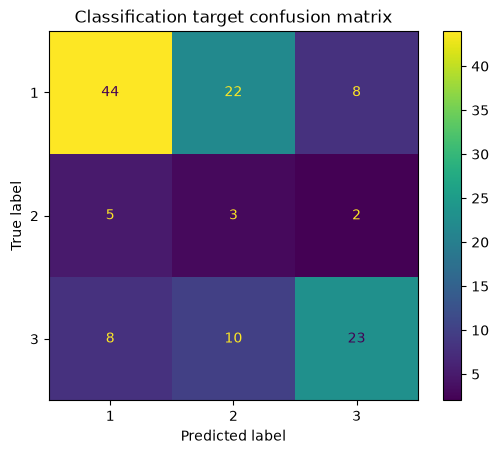

In [32]:
ConfusionMatrixDisplay.from_predictions(
    yc_test,
    cls_pred,
    cmap=None)
    
plt.title("Classification target confusion matrix")
plt.show()

In [36]:
# Create a pipeline that generates polynomial features and trains a logistic regression model
pipeline_poly_log = Pipeline([
    ("prep", preprocessor),
    ('poly', PolynomialFeatures(degree=3)),  # Generate polynomial features
    ('logistic', LogisticRegression() )     # Train logistic regression model
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


scoring = {
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro'
}


cv_results = cross_validate(
    pipeline_poly_log,
    Xc_train,
    yc_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("=== Cross-Validation Results (Train Fold Means) ===")
print(f"Mean Balanced Accuracy: {np.mean(cv_results['test_balanced_accuracy']):.4f} ± {np.std(cv_results['test_balanced_accuracy']):.4f}")
print(f"Mean Macro F1:          {np.mean(cv_results['test_f1_macro']):.4f} ± {np.std(cv_results['test_f1_macro']):.4f}")
print("-" * 50)


pipeline_poly_log.fit(Xc_train, yc_train)

cls_pred = pipeline_poly_log.predict(Xc_test)
cls_proba = pipeline_poly_log.predict_proba(Xc_test)

print("=== Hold-out Test Set Results ===")
print(classification_report(yc_test, cls_pred))
print("Balanced accuracy:", balanced_accuracy_score(yc_test, cls_pred))
print("Macro F1:", f1_score(yc_test, cls_pred, average="macro"))

=== Cross-Validation Results (Train Fold Means) ===
Mean Balanced Accuracy: 0.5060 ± 0.0449
Mean Macro F1:          0.5326 ± 0.0506
--------------------------------------------------
=== Hold-out Test Set Results ===
              precision    recall  f1-score   support

           1       0.76      0.77      0.77        74
           2       0.40      0.40      0.40        10
           3       0.65      0.63      0.64        41

    accuracy                           0.70       125
   macro avg       0.60      0.60      0.60       125
weighted avg       0.70      0.70      0.70       125

Balanced accuracy: 0.6014722039112282
Macro F1: 0.6023586599276383


In [42]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, balanced_accuracy_score, f1_score

# 1. Базовий пайплайн
pipeline_poly_log = Pipeline([
    ("prep", preprocessor),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("logistic", LogisticRegression(
        class_weight="balanced", # Обов'язково для незбалансованих класів
        solver="saga",           # saga підтримує L1, L2 та ElasticNet регуляризацію
        max_iter=5000, 
        random_state=RANDOM_STATE
    ))
])

# 2. Сітка гіперпараметрів (Param Grid)
param_grid = {
    # Зменшуємо degree до 1 і 2. degree=3 майже завжди викликає overfitting
    "poly__degree": [1, 2],
    
    # Сила регуляризації (менші значення C = сильніша регуляризація)
    "logistic__C": [0.01, 0.1, 1.0, 10.0],
    
    # Тип регуляризації: L2 (Ridge), L1 (Lasso для відбору ознак) або ElasticNet
    "logistic__penalty": ["l1", "l2", "elasticnet"],
    "logistic__l1_ratio": [0.5]  # Використовується тільки якщо penalty='elasticnet'
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 3. GridSearchCV з фокусом на balanced_accuracy (або f1_macro)
grid_search = GridSearchCV(
    estimator=pipeline_poly_log,
    param_grid=param_grid,
    cv=cv,
    scoring="balanced_accuracy",  # Оптимізуємо саме за цією метрикою
    n_jobs=-1,
    verbose=1
)

# 4. Навчаємо та шукаємо кращі параметри
grid_search.fit(Xc_train, yc_train)

print(f"Кращі параметри: {grid_search.best_params_}")
print(f"Кращий Balanced Accuracy на CV: {grid_search.best_score_:.4f}")

# 5. Краща модель вже автозафічена на Xc_train
best_pipeline = grid_search.best_estimator_

# 6. Оцінка на Hold-out тестовій вибірці
cls_pred = best_pipeline.predict(Xc_test)
cls_proba = best_pipeline.predict_proba(Xc_test)

print("\n=== Hold-out Test Set Results (Best Model) ===")
print(classification_report(yc_test, cls_pred))
print("Balanced accuracy:", balanced_accuracy_score(yc_test, cls_pred))
print("Macro F1:", f1_score(yc_test, cls_pred, average="macro"))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Кращі параметри: {'logistic__C': 1.0, 'logistic__l1_ratio': 0.5, 'logistic__penalty': 'elasticnet', 'poly__degree': 2}
Кращий Balanced Accuracy на CV: 0.5588

=== Hold-out Test Set Results (Best Model) ===
              precision    recall  f1-score   support

           1       0.78      0.64      0.70        74
           2       0.17      0.40      0.24        10
           3       0.62      0.63      0.63        41

    accuracy                           0.62       125
   macro avg       0.53      0.56      0.52       125
weighted avg       0.68      0.62      0.64       125

Balanced accuracy: 0.5564271588661832
Macro F1: 0.523474267944687


In [43]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, balanced_accuracy_score, f1_score

# 1. Побудова пайплайну: Preprocessing -> PCA -> Logistic Regression
pipeline_pca_log = Pipeline([
    ("prep", preprocessor),
    ("pca", PCA(random_state=RANDOM_STATE)),
    ("logistic", LogisticRegression(
        class_weight="balanced", # Враховуємо дисбаланс класів
        solver="lbfgs", 
        max_iter=2000, 
        random_state=RANDOM_STATE
    ))
])

# 2. Сітка гіперпараметрів для пошуку
param_grid = {
    # Кількість головних компонент (від 2 до 9, оскільки у нас 9 дескрипторів)
    "pca__n_components": [2, 3, 4, 5, 6, 7, 8, 9],
    
    # Регуляризація L2 для логістичної регресії
    "logistic__C": [0.01, 0.1, 1.0, 10.0, 100.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 3. Налаштування GridSearchCV
grid_search_pca = GridSearchCV(
    estimator=pipeline_pca_log,
    param_grid=param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    verbose=1
)

# 4. Навчання та пошук кращої комбінації
grid_search_pca.fit(Xc_train, yc_train)

print(f"Кращі параметри: {grid_search_pca.best_params_}")
print(f"Кращий Balanced Accuracy на CV: {grid_search_pca.best_score_:.4f}")

# 5. Оцінка кращої моделі на hold-out тесті
best_pca_pipeline = grid_search_pca.best_estimator_

cls_pred_pca = best_pca_pipeline.predict(Xc_test)
cls_proba_pca = best_pca_pipeline.predict_proba(Xc_test)

print("\n=== Hold-out Test Set Results (PCA + Logistic) ===")
print(classification_report(yc_test, cls_pred_pca))
print("Balanced accuracy:", balanced_accuracy_score(yc_test, cls_pred_pca))
print("Macro F1:", f1_score(yc_test, cls_pred_pca, average="macro"))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Кращі параметри: {'logistic__C': 0.01, 'pca__n_components': 6}
Кращий Balanced Accuracy на CV: 0.5258

=== Hold-out Test Set Results (PCA + Logistic) ===
              precision    recall  f1-score   support

           1       0.80      0.59      0.68        74
           2       0.14      0.50      0.22        10
           3       0.57      0.49      0.53        41

    accuracy                           0.55       125
   macro avg       0.50      0.53      0.48       125
weighted avg       0.67      0.55      0.59       125

Balanced accuracy: 0.5274664908811251
Macro F1: 0.4769028514438551


In [44]:
explained_variance = best_pca_pipeline.named_steps["pca"].explained_variance_ratio_
print(f"Пояснена дисперсія по компонентах: {explained_variance}")
print(f"Загальна пояснена дисперсія: {sum(explained_variance):.2%}")

Пояснена дисперсія по компонентах: [0.64828741 0.11946749 0.09293591 0.04670982 0.03408734 0.02877819]
Загальна пояснена дисперсія: 97.03%


In [41]:
# TEMPLATE — replace placeholders with your fitted models.

test = pd.read_csv("QSAR_challenge_test_20pct_NO_TARGETS.csv")
submission = pd.DataFrame({
    "sample_id": test["sample_id"]
})
X_full = df[feature_names]
y_full_reg = df["regression_target"].values
y_full_cls = df["classification_target"].values
preprocessor_full = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

X_full_prep = preprocessor_full.fit_transform(X_full)

gam_final = LinearGAM(gam_terms)
gam_final.gridsearch(X_full_prep, y_full_reg, progress=False)

X_hidden_challenge = test[feature_names]

X_hidden_prep = preprocessor_full.transform(X_hidden_challenge)

submission["regression_prediction"] = gam_final.predict(X_hidden_prep)
pipeline_poly_log.fit(X_full, y_full_cls)
cls_proba = pipeline_poly_log.predict_proba(X_hidden_challenge)
submission["classification_prediction"] = pipeline_poly_log.classes_[np.argmax(cls_proba, axis=1)].astype(int)
display(submission)
submission.to_csv("submission_Fisun_Yelyzaveta.csv", index=False)

,sample_id,regression_prediction,classification_prediction
0,78-79-5,0.794585,1
1,16606-02-3,3.811858,1
2,111-44-4,0.742261,1
3,107-05-1,0.591784,1
4,555-03-3,0.729393,1
...,...,...,...
151,41464-40-8,4.270050,1
152,89-59-8,1.387443,1
153,88-75-5,0.547994,1
154,41083-11-8,3.462131,2
